<img src="https://github.com/hernancontigiani/ceia_memorias_especializacion/raw/master/Figures/logoFIUBA.jpg" width="500" align="center">

# Procesamiento de Lenguaje Natural
## Desafío 4: Traductor inglés-español

**Objetivo.** Replicar el traductor secuencia a secuencia visto en clase, ampliar los datos y la longitud máxima de las oraciones, comparar el efecto del tamaño de las capas LSTM y analizar ejemplos y métricas.

El cuaderno conserva la idea del material de clase: un encoder LSTM resume la oración en inglés y un decoder LSTM produce la traducción en español token a token. La comparación usa exactamente la misma partición de entrenamiento y validación para que el número de unidades sea la principal diferencia.


### 1. Dependencias y configuración

Se fijan las semillas para facilitar la repetición. El entrenamiento puede tardar varios minutos; si se desea una prueba rápida, se puede reducir `MAX_NUM_SENTENCES` y `EPOCHS`, aunque eso también reduce la calidad y la fuerza de la comparación.


In [17]:
import os
import random
import re
import zipfile
from pathlib import Path
from urllib.request import urlretrieve

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.layers import Input, LSTM, Dense, Embedding
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

SEED = 40
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

MAX_NUM_SENTENCES = 50_000  # 5 veces más pares que el ejemplo base de clase (10.000)
MAX_VOCAB_SIZE = 12_000
MAX_INPUT_LEN = 30          # el ejemplo base usaba 20 tokens
MAX_OUTPUT_LEN = 32         # deja espacio para <sos> y <eos>
BATCH_SIZE = 128
EPOCHS = 25
VALIDATION_SPLIT = 0.15

print("TensorFlow:", tf.__version__)
gpus = tf.config.list_physical_devices("GPU")
print("GPU detectada por TensorFlow:", gpus if gpus else "No; se usará CPU")
if gpus:
    # La GPU se usa automáticamente cuando TensorFlow tiene soporte CUDA.
    # El crecimiento gradual evita reservar toda la memoria al iniciar.
    for gpu in gpus:
        try:
            tf.config.experimental.set_memory_growth(gpu, True)
        except RuntimeError:
            pass  # La configuración ya quedó fijada si TensorFlow inicializó la GPU.
print("Dispositivo(s):", tf.config.list_physical_devices())


TensorFlow: 2.21.0
GPU detectada por TensorFlow: No; se usará CPU
Dispositivo(s): [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


### 2. Descarga y preparación del corpus

Usamos el corpus inglés-español `spa-eng` de TensorFlow. Se conserva el orden aleatorio con semilla fija y se separa validación antes de ajustar los tokenizadores: así las estadísticas del vocabulario se aprenden solo con entrenamiento. Las oraciones que exceden el largo fijado se truncan con padding; por eso también evaluaremos la longitud como limitación.


In [18]:
DATA_DIR = Path("spa-eng")
ZIP_PATH = Path("spa-eng.zip")
DATA_URL = "https://storage.googleapis.com/download.tensorflow.org/data/spa-eng.zip"

if not (DATA_DIR / "spa.txt").exists():
    if not ZIP_PATH.exists():
        print("Descargando corpus...")
        urlretrieve(DATA_URL, ZIP_PATH)
    with zipfile.ZipFile(ZIP_PATH) as archive:
        archive.extractall(".")

with open(DATA_DIR / "spa.txt", encoding="utf-8") as file:
    pairs = [line.strip().split("\t")[:2] for line in file if "\t" in line]
pairs = [(en, es) for en, es in pairs if en and es]
random.Random(SEED).shuffle(pairs)
pairs = pairs[:MAX_NUM_SENTENCES]

input_sentences = [en for en, _ in pairs]
target_sentences = [es for _, es in pairs]
split_at = int(len(pairs) * (1 - VALIDATION_SPLIT))
train_en, val_en = input_sentences[:split_at], input_sentences[split_at:]
train_es, val_es = target_sentences[:split_at], target_sentences[split_at:]

print(f"Pares usados: {len(pairs):,}; entrenamiento: {len(train_en):,}; validación: {len(val_en):,}")
print("Ejemplo:", train_en[0], "→", train_es[0])


Pares usados: 50,000; entrenamiento: 42,500; validación: 7,500
Ejemplo: Tom has already made up his mind. → Tom ya se decidió.


In [19]:
# Cada idioma tiene su propio vocabulario. Los tokens de inicio/fin son parte del idioma destino.
input_tokenizer = Tokenizer(num_words=MAX_VOCAB_SIZE, filters='')
input_tokenizer.fit_on_texts(train_en)

target_tokenizer = Tokenizer(num_words=MAX_VOCAB_SIZE, filters='')
target_tokenizer.fit_on_texts(["<sos> " + text + " <eos>" for text in train_es])

input_vocab_size = min(MAX_VOCAB_SIZE, len(input_tokenizer.word_index) + 1)
target_vocab_size = min(MAX_VOCAB_SIZE, len(target_tokenizer.word_index) + 1)
sos_id = target_tokenizer.word_index["<sos>"]
eos_id = target_tokenizer.word_index["<eos>"]

def encode_sources(texts):
    seqs = input_tokenizer.texts_to_sequences(texts)
    return pad_sequences(seqs, maxlen=MAX_INPUT_LEN, padding="post", truncating="post")

def encode_targets(texts):
    # Decoder recibe <sos> + frase; el objetivo es frase + <eos>.
    dec_in = target_tokenizer.texts_to_sequences(["<sos> " + text for text in texts])
    dec_out = target_tokenizer.texts_to_sequences([text + " <eos>" for text in texts])
    return (
        pad_sequences(dec_in, maxlen=MAX_OUTPUT_LEN, padding="post", truncating="post"),
        pad_sequences(dec_out, maxlen=MAX_OUTPUT_LEN, padding="post", truncating="post"),
    )

X_train = encode_sources(train_en)
X_val = encode_sources(val_en)
Yin_train, Y_train = encode_targets(train_es)
Yin_val, Y_val = encode_targets(val_es)

print(f"Vocabulario EN: {input_vocab_size:,}; ES: {target_vocab_size:,}")
print(f"Longitudes máximas: EN={MAX_INPUT_LEN}, ES={MAX_OUTPUT_LEN}")
print("Tokens especiales:", {"<sos>": sos_id, "<eos>": eos_id})


Vocabulario EN: 12,000; ES: 12,000
Longitudes máximas: EN=30, ES=32
Tokens especiales: {'<sos>': 1, '<eos>': 2}


### 3. Modelo encoder-decoder y entrenamiento

Se usa pérdida de entropía cruzada dispersa, que evita expandir cada etiqueta a un vector one-hot. El peso de muestra vale cero en los tokens de padding, así la pérdida y la exactitud no se benefician artificialmente por predecir ceros. Se entrenan dos configuraciones (`128` y `256` unidades) con los mismos datos, orden, épocas máximas y callbacks. El decoder usa *teacher forcing*, como en el ejemplo de clase.


### GPU y modelos guardados

TensorFlow detecta la GPU al iniciar y usa automáticamente los dispositivos compatibles. El entrenamiento guarda los pesos y el historial en `Desafio_4/modelos_traductor/` (o `modelos_traductor/` si se ejecuta desde otra carpeta). Antes de cada entrenamiento compara la firma del corpus y la configuración: si encuentra un modelo compatible, carga sus pesos y se saltea el entrenamiento; si no coincide, entrena y reemplaza ese archivo.

Los archivos `.weights.h5` guardan los pesos entrenados; el notebook reconstruye la arquitectura y los tokenizadores desde los datos para cargarlos. En Google Colab la carpeta local desaparece al cerrar la sesión, por lo que para conservar los modelos entre sesiones hay que montar Drive o descargar esa carpeta.


In [20]:
def build_seq2seq(units):
    # Encoder: transforma la oración fuente en estados oculto y de memoria.
    encoder_tokens = Input(shape=(MAX_INPUT_LEN,), name="encoder_tokens")
    encoder_embedding = Embedding(input_vocab_size, 128, mask_zero=True, name="encoder_embedding")
    encoder_lstm = LSTM(units, return_state=True, name="encoder_lstm")
    _, state_h, state_c = encoder_lstm(encoder_embedding(encoder_tokens))

    # Decoder: predice la traducción condicionado por los estados del encoder.
    decoder_tokens = Input(shape=(MAX_OUTPUT_LEN,), name="decoder_tokens")
    decoder_embedding = Embedding(target_vocab_size, 128, mask_zero=True, name="decoder_embedding")
    decoder_lstm = LSTM(units, return_sequences=True, return_state=True, name="decoder_lstm")
    decoder_outputs, _, _ = decoder_lstm(
        decoder_embedding(decoder_tokens), initial_state=[state_h, state_c]
    )
    output_layer = Dense(target_vocab_size, activation="softmax", name="word_probabilities")
    probabilities = output_layer(decoder_outputs)
    model = Model([encoder_tokens, decoder_tokens], probabilities)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="sparse_categorical_crossentropy",
        weighted_metrics=[tf.keras.metrics.SparseCategoricalAccuracy(name="token_accuracy")],
    )

    # Submodelos para inferencia: comparten las capas entrenables del modelo completo.
    encoder_model = Model(encoder_tokens, [state_h, state_c])
    step_token = Input(shape=(1,), name="step_token")
    step_h = Input(shape=(units,), name="step_h")
    step_c = Input(shape=(units,), name="step_c")
    step_output, next_h, next_c = decoder_lstm(
        decoder_embedding(step_token), initial_state=[step_h, step_c]
    )
    step_probabilities = output_layer(step_output)
    decoder_model = Model([step_token, step_h, step_c], [step_probabilities, next_h, next_c])
    return model, encoder_model, decoder_model

def sample_weights(targets):
    # Ignora las posiciones de padding al calcular pérdida y exactitud.
    return (targets != 0).astype("float32")


In [21]:
import hashlib
import json

# Firma de datos y configuración: evita reutilizar pesos de otro corpus o vocabulario.
DATA_SIGNATURE = hashlib.sha256(
    "\n".join(f"{en}\t{es}" for en, es in pairs).encode("utf-8")
).hexdigest()
MODEL_DIR = Path("Desafio_4") / "modelos_traductor" if Path("Desafio_4").exists() else Path("modelos_traductor")
MODEL_DIR.mkdir(parents=True, exist_ok=True)
print("Carpeta de modelos:", MODEL_DIR.resolve())

configs = [128, 256]
models, encoders, decoders, histories, results = {}, {}, {}, {}, []

for units in configs:
    print(f"\nRevisando modelo de {units} unidades LSTM...")
    model, encoder_model, decoder_model = build_seq2seq(units)
    weights_path = MODEL_DIR / f"traductor_{units}_unidades.weights.h5"
    metadata_path = MODEL_DIR / f"traductor_{units}_unidades.json"
    expected_config = {
        "units": units,
        "data_signature": DATA_SIGNATURE,
        "max_num_sentences": MAX_NUM_SENTENCES,
        "max_vocab_size": MAX_VOCAB_SIZE,
        "max_input_len": MAX_INPUT_LEN,
        "max_output_len": MAX_OUTPUT_LEN,
        "input_vocab_size": input_vocab_size,
        "target_vocab_size": target_vocab_size,
        "embedding_dim": 128,
    }

    history_data = None
    loaded = False
    if weights_path.exists() and metadata_path.exists():
        try:
            saved = json.loads(metadata_path.read_text(encoding="utf-8"))
            if saved.get("config") == expected_config:
                model.load_weights(weights_path)
                history_data = saved["history"]
                print(f"Encontrado y compatible: {weights_path}. Se omite el entrenamiento.")
                loaded = True
            else:
                print("Hay un modelo guardado, pero su configuración/datos no coinciden; se volverá a entrenar.")
        except Exception as error:
            print(f"No se pudo cargar el modelo guardado ({error}); se volverá a entrenar.")
    else:
        print("No hay un modelo guardado compatible; se entrenará esta configuración.")

    if not loaded:
        callbacks = [
            ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5, verbose=1),
            EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True, verbose=1),
        ]
        history = model.fit(
            [X_train, Yin_train], Y_train,
            sample_weight=sample_weights(Y_train),
            validation_data=([X_val, Yin_val], Y_val, sample_weights(Y_val)),
            batch_size=BATCH_SIZE, epochs=EPOCHS, callbacks=callbacks, verbose=1,
        )
        history_data = {key: [float(value) for value in values]
                        for key, values in history.history.items()}
        model.save_weights(weights_path)
        metadata_path.write_text(json.dumps({
            "config": expected_config,
            "history": history_data,
            "tensorflow_version": tf.__version__,
        }, ensure_ascii=False, indent=2), encoding="utf-8")
        print(f"Pesos guardados en: {weights_path}")

    # Se conservan las curvas y métricas originales también al cargar un modelo existente.
    history = tf.keras.callbacks.History()
    history.history = history_data
    best_epoch = int(np.argmin(history.history["val_loss"])) + 1
    best_val_loss = float(min(history.history["val_loss"]))
    best_val_acc = float(history.history["val_token_accuracy"][best_epoch - 1])
    models[units], encoders[units], decoders[units], histories[units] = model, encoder_model, decoder_model, history
    results.append({
        "unidades LSTM": units,
        "parámetros": model.count_params(),
        "mejor época": best_epoch,
        "pérdida validación": best_val_loss,
        "exactitud por token (validación)": best_val_acc,
    })

results_df = pd.DataFrame(results).sort_values("pérdida validación").reset_index(drop=True)
display(results_df)


Carpeta de modelos: D:\GONZALO\FACULTAD\Esp_IA\Procesamiento_lenguaje\TPS\PNL_cuervo\Desafio_4\modelos_traductor

Revisando modelo de 128 unidades LSTM...


d:\GONZALO\FACULTAD\Esp_IA\Procesamiento_lenguaje\TPS\PNL_cuervo\.venv\Lib\site-packages\keras\src\saving\saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam_4', because it has 2 variables whereas the saved optimizer has 22 variables. 
  saveable.load_own_variables(store)


Encontrado y compatible: modelos_traductor\traductor_128_unidades.weights.h5. Se omite el entrenamiento.

Revisando modelo de 256 unidades LSTM...
Encontrado y compatible: modelos_traductor\traductor_256_unidades.weights.h5. Se omite el entrenamiento.


d:\GONZALO\FACULTAD\Esp_IA\Procesamiento_lenguaje\TPS\PNL_cuervo\.venv\Lib\site-packages\keras\src\saving\saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam_5', because it has 2 variables whereas the saved optimizer has 22 variables. 
  saveable.load_own_variables(store)


,unidades LSTM,parámetros,mejor época,pérdida validación,exactitud por token (validación)
0,128,4883168,24,3.23240,0.442367
1,256,6944480,24,3.30259,0.449314


### 4. Comparación de curvas

La pérdida de validación permite comparar el error de predicción de tokens en oraciones que no participaron del ajuste. La exactitud por token indica qué fracción de las palabras objetivo se predice correctamente. Ninguna de las dos métricas equivale directamente a la calidad semántica de una oración completa: pequeños cambios en el orden o una palabra pueden afectar mucho una traducción correcta.


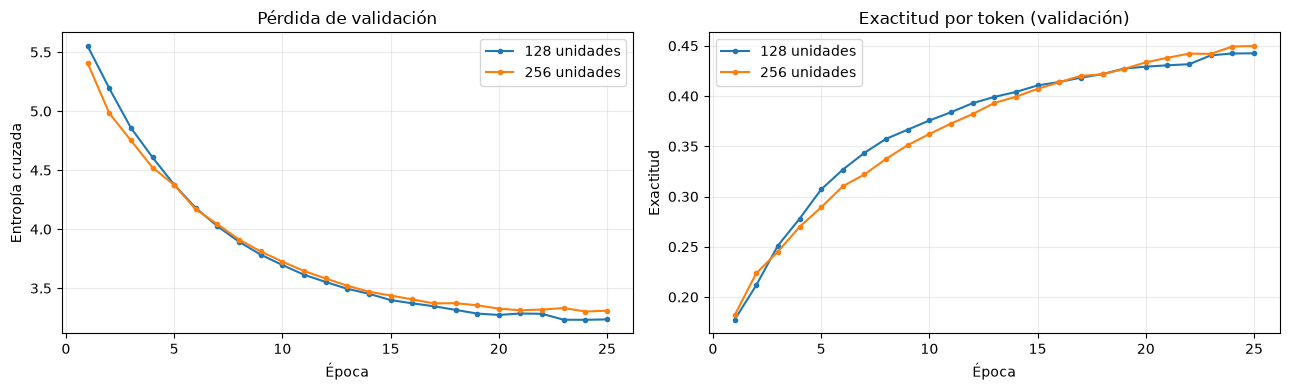

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for units, history in histories.items():
    epochs = range(1, len(history.history["loss"]) + 1)
    axes[0].plot(epochs, history.history["val_loss"], marker=".", label=f"{units} unidades")
    axes[1].plot(epochs, history.history["val_token_accuracy"], marker=".", label=f"{units} unidades")
axes[0].set(title="Pérdida de validación", xlabel="Época", ylabel="Entropía cruzada")
axes[1].set(title="Exactitud por token (validación)", xlabel="Época", ylabel="Exactitud")
for ax in axes:
    ax.grid(alpha=.25)
    ax.legend()
plt.tight_layout()
plt.show()


### 5. Traducción greedy y evaluación de ejemplos

En cada paso, el decoder elige la palabra de mayor probabilidad (*greedy decoding*) y se detiene al emitir `<eos>` o alcanzar el límite. La primera tabla muestra cinco pares de validación. También probamos cinco frases ingresadas manualmente. Sacamos BLEU corpus sobre una muestra fija de hasta 500 frases de validación como referencia automática adicional; BLEU compara n-gramas con una única traducción de referencia y debe interpretarse junto con la inspección humana.


In [23]:
idx_to_target = {idx: word for word, idx in target_tokenizer.word_index.items() if idx < target_vocab_size}

def translate_with_model(text, units):
    source = encode_sources([text])
    h, c = encoders[units](source, training=False)
    current = np.array([[sos_id]], dtype="int32")
    words = []
    for _ in range(MAX_OUTPUT_LEN):
        decoder_input = tf.convert_to_tensor(current, dtype=tf.int32)
        probs, h, c = decoders[units]([decoder_input, h, c], training=False)
        token_id = int(np.argmax(probs[0, 0]))
        if token_id == eos_id or token_id == 0:
            break
        token = idx_to_target.get(token_id, "")
        if token and token != "<sos>":
            words.append(token)
        current[0, 0] = token_id
    return " ".join(words)

best_units = int(results_df.iloc[0]["unidades LSTM"])
example_ids = np.random.default_rng(SEED).choice(len(val_en), size=5, replace=False)
examples = pd.DataFrame([
    {"Inglés (referencia)": val_en[i], "Español real": val_es[i],
     f"Predicción ({best_units} unidades)": translate_with_model(val_en[i], best_units)}
    for i in example_ids
])
display(examples)

custom_sentences = [
    "How are you?",
    "Where is the train station?",
    "I love learning languages.",
    "Can you help me?",
    "The weather is beautiful today.",
]
display(pd.DataFrame({"Inglés": custom_sentences,
                      "Español generado": [translate_with_model(s, best_units) for s in custom_sentences]}))


,Inglés (referencia),Español real,Predicción (128 unidades)
0,Tom wondered how much tequila Mary could drink...,Tom se preguntaba cuánto tequila podría beber ...,tom se preguntaba cuánto debería ir a mary o l...
1,Open the safe.,Abra la caja fuerte.,tres
2,Tom got off the elevator.,Tom se bajó del ascensor.,tom se
3,It cannot be true.,No puede ser cierto.,no puede ser verdad.
4,The letter got lost in the mail.,La carta se perdió entre el correo.,el tren se ha estado en el


,Inglés,Español generado
0,How are you?,puedes
1,Where is the train station?,¿dónde está el único que viene.
2,I love learning languages.,le encanta bailar.
3,Can you help me?,podría estar aquí.
4,The weather is beautiful today.,el clima de


In [24]:
# BLEU puede no estar instalado en un entorno local; se informa si está disponible.
try:
    from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction
    references, hypotheses = [], []
    bleu_indices = np.linspace(0, len(val_en) - 1, min(500, len(val_en)), dtype=int)
    for i in bleu_indices:
        source, reference = val_en[i], val_es[i]
        prediction = translate_with_model(source, best_units)
        references.append([reference.lower().split()])
        hypotheses.append(prediction.lower().split())
    bleu = corpus_bleu(references, hypotheses, smoothing_function=SmoothingFunction().method1)
    print(f"BLEU corpus en muestra de validación ({best_units} unidades): {bleu:.4f}")
except ImportError:
    print("Instalá nltk para calcular BLEU (pip install nltk). La comparación principal sigue disponible en la tabla.")


BLEU corpus en muestra de validación (128 unidades): 0.0567


### 6. Conclusión e interpretación

La siguiente celda resume los valores observados por el entrenamiento. Ejecutar nuevamente el cuaderno puede producir pequeñas variaciones según el hardware, el backend y la versión de TensorFlow.


In [25]:
ordered = results_df.sort_values("unidades LSTM")
small, large = ordered.iloc[0], ordered.iloc[-1]
loss_change = (large["pérdida validación"] - small["pérdida validación"]) / small["pérdida validación"] * 100
acc_change = large["exactitud por token (validación)"] - small["exactitud por token (validación)"]
winner = results_df.iloc[0]

print("CONCLUSIÓN")
print(f"- La configuración con menor pérdida de validación fue la de {int(winner['unidades LSTM'])} unidades "
      f"(pérdida={winner['pérdida validación']:.4f}; exactitud por token="
      f"{winner['exactitud por token (validación)']:.3f}).")
print(f"- Al pasar de {int(small['unidades LSTM'])} a {int(large['unidades LSTM'])} unidades, "
      f"la pérdida cambió {loss_change:+.1f}% y la exactitud por token cambió {acc_change:+.3f}.")
print("- Más unidades aumentan la capacidad y el costo computacional, pero no garantizan una mejora: "
      "la decisión debe apoyarse en validación y en revisar las traducciones generadas.")
print("- Las frases del corpus permiten medir generalización dentro de un dominio parecido al entrenamiento. "
      "Las frases manuales sirven como prueba cualitativa, no como una métrica estadística.")
print("- Limitaciones: corpus acotado y sesgado, vocabulario truncado, límite de longitud, ausencia de atención, "
      "decodificación greedy y una única referencia por frase. El decoder puede repetir u omitir palabras y "
      "tener dificultades con nombres propios, expresiones idiomáticas y oraciones largas.")


CONCLUSIÓN
- La configuración con menor pérdida de validación fue la de 128 unidades (pérdida=3.2324; exactitud por token=0.442).
- Al pasar de 128 a 256 unidades, la pérdida cambió +2.2% y la exactitud por token cambió +0.007.
- Más unidades aumentan la capacidad y el costo computacional, pero no garantizan una mejora: la decisión debe apoyarse en validación y en revisar las traducciones generadas.
- Las frases del corpus permiten medir generalización dentro de un dominio parecido al entrenamiento. Las frases manuales sirven como prueba cualitativa, no como una métrica estadística.
- Limitaciones: corpus acotado y sesgado, vocabulario truncado, límite de longitud, ausencia de atención, decodificación greedy y una única referencia por frase. El decoder puede repetir u omitir palabras y tener dificultades con nombres propios, expresiones idiomáticas y oraciones largas.


### Conclusión final

El modelo seq2seq aprende correspondencias inglés-español y permite producir traducciones de forma autoregresiva. La comparación entre 128 y 256 unidades cuantifica cómo cambia la pérdida y la exactitud por token al aumentar la capacidad del modelo; la tabla de ejemplos ayuda a verificar si esa diferencia se refleja en traducciones legibles. Los números concretos se completan al ejecutar el entrenamiento, ya que dependen de la versión de TensorFlow y del hardware disponible. Para mejorar el enfoque, los pasos más prometedores serían agregar atención, evaluar con varias referencias y probar beam search o embeddings preentrenados.
